In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(215)
raw = pd.read_csv("DataSet.csv")
df  = pd.read_csv("CleanedDataSet.csv")
print(raw.shape, df.shape)

(1698, 14) (1698, 29)


## 1. Load and log transforms

In [3]:
print(raw.shape, df.shape)

df["log_budget"]  = np.log(df["Budget"])
df["log_revenue"] = np.log(df["Revenue"])
df["log_screens"] = np.log(df["Number of Screens"])

(1698, 14) (1698, 29)


## 2. Why the log scale (motivation)

In [5]:
cols = ["Budget", "Revenue", "ROI", "log_budget", "log_revenue"]
print(df[cols].describe().T[["mean", "50%", "min", "max"]].round(1))
print("skew:", df[cols].skew().round(3).to_dict())
print("films below budget:", (df["Revenue"] < df["Budget"]).sum())

                    mean         50%       min           max
Budget       150123218.5  55000000.0  325000.0  2.100000e+09
Revenue      237806127.4  12500000.0    7250.0  8.016120e+09
ROI                  0.8         0.3       0.0  8.400000e+00
log_budget          17.7        17.8      12.7  2.150000e+01
log_revenue         16.4        16.3       8.9  2.280000e+01
skew: {'Budget': 3.304, 'Revenue': 5.82, 'ROI': 2.226, 'log_budget': -0.301, 'log_revenue': -0.006}
films below budget: 1225


**📌 Inference :**
> This section showed us why the log scale is necessary: revenue has skew 5.82 while log revenue has skew 0.006, and the mean (23.8 crore) is 19 times the median (1.25 crore), so the average Bollywood film does not exist. 

> We also found that 1,225 of 1,698 films (72%) never recover their budget, which tells us profits live almost entirely in the tail and even budgets are skewed (3.30) before any output is measured.

## 3. Visual proof: raw spike vs log bell

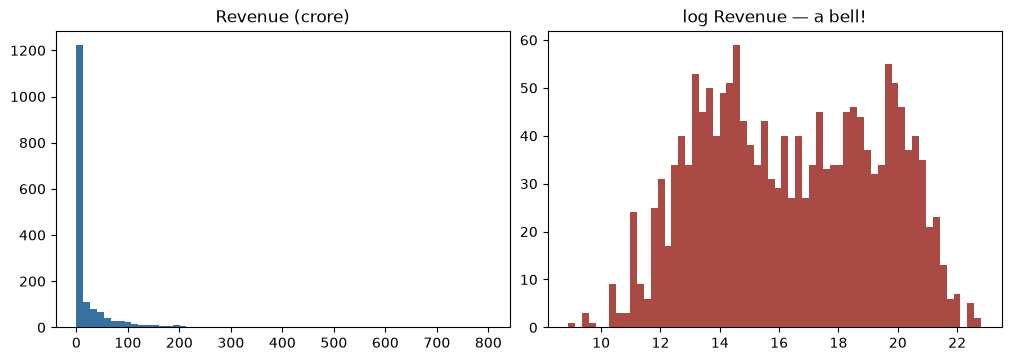

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
ax[0].hist(df["Revenue"]/1e7, bins=60, color="#3771a0"); ax[0].set_title("Revenue (crore)")
ax[1].hist(df["log_revenue"], bins=60, color="#aa4a44"); ax[1].set_title("log Revenue — a bell!")
plt.show()

**📌 Inference :** 
> The histogram pair makes the same point visually: on the raw scale the histogram is one spike with an invisible tail, but on the log scale a near perfect bell appears, which told us before any fitting that a normal distribution applied to log revenue is the right candidate.

## 4. χ² contest on Revenue (six families)
**Uniform, Normal, Exponential, Chi-square, Student-t, and Normal-on-log.**

In [11]:
rev = df["Revenue"].values.astype(float)

def chisq_gof(data, name, params, m, k=10):
    """χ² GOF: bin by the fitted model's own deciles; m = estimated parameters."""
    d = getattr(stats, name)
    edges = d.ppf(np.linspace(0, 1, k + 1), *params)
    edges[0], edges[-1] = -np.inf, np.inf
    obs = np.histogram(data, bins=edges)[0]
    exp = np.full(k, len(data) / k)
    stat, p = stats.chisquare(obs, exp, ddof=m)
    return stat, p, k - 1 - m, obs

cands = []
p_u = stats.uniform.fit(rev)
cands.append(("Uniform ", np.sum(stats.uniform.logpdf(rev, *p_u)), "uniform", p_u, 2))
p_n = stats.norm.fit(rev)
cands.append(("Normal ", np.sum(stats.norm.logpdf(rev, *p_n)), "norm", p_n, 2))
p_e = stats.expon.fit(rev, floc=0)
cands.append(("Exponential", np.sum(stats.expon.logpdf(rev, *p_e)), "expon", p_e, 1))
p_c = stats.chi2.fit(rev, floc=0)
cands.append(("Chi-square family", np.sum(stats.chi2.logpdf(rev, *p_c)), "chi2", p_c, 2))
p_t = stats.t.fit(rev)
cands.append(("t-distribution", np.sum(stats.t.logpdf(rev, *p_t)), "t", p_t, 3))
ly  = np.log(rev); mu, sd = ly.mean(), ly.std(ddof=0)
ll_ln = np.sum(stats.norm.logpdf(ly, mu, sd)) - ly.sum()
cands.append(("Normal on log = lognormal", ll_ln, "lognorm", (sd, 0, np.exp(mu)), 2))

for label, ll, nm, par, m in cands:
    chi2, p, dfree, obs = chisq_gof(rev, nm, par, m)
    print(f"{label:28s} LL={ll:10.0f}  chi2={chi2:8.1f} (df={dfree})  bins={obs}")
print("fitted dials: t df =", round(p_t[0], 2), "| chi2 df =", round(p_c[0], 2))

Uniform                      LL=    -38722  chi2= 12492.7 (df=7)  bins=[1549   95   32    8    7    0    1    4    1    1]
Normal                       LL=    -36767  chi2=  6217.7 (df=7)  bins=[   0    0    0 1130  191   91   76   53   51  106]
Exponential                  LL=    -34447  chi2=  4071.0 (df=8)  bins=[945 122  69  70  54  49  37  53  87 212]
Chi-square family            LL=    -32307  chi2=   567.2 (df=7)  bins=[ 21 375 320 172 140 115 129 111 148 167]
t-distribution               LL=    -33479  chi2=  1895.6 (df=6)  bins=[  0   0   0   0   0 356 258 234 404 446]
Normal on log = lognormal    LL=    -32140  chi2=   135.5 (df=7)  bins=[180 241 196 135 108 106 124 169 242 197]
fitted dials: t df = 0.28 | chi2 df = 0.5


**See WHERE each curve fails** — fitted curves drawn on the data:

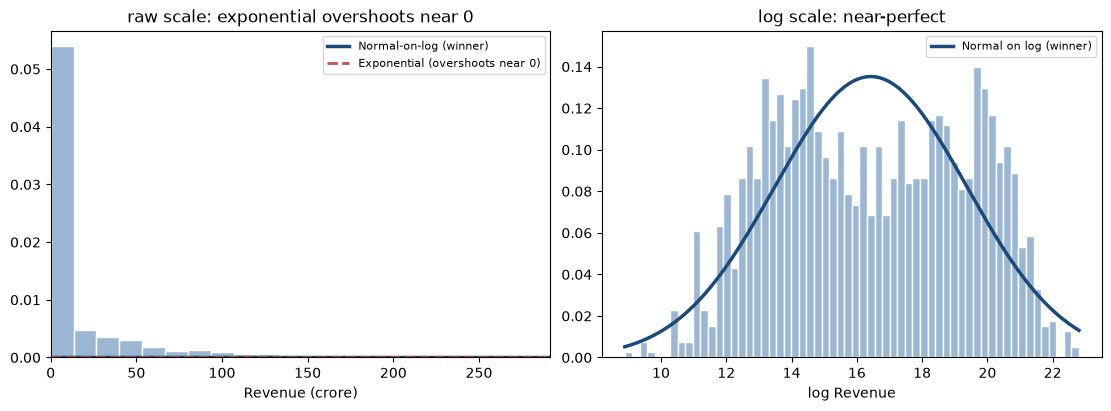

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)

# left: raw scale — bars neutral, winner dark blue, loser red dashed
ax[0].hist(rev/1e7, bins=60, density=True, color="#9bb7d4", edgecolor="white")
xs = np.linspace(0, np.quantile(rev, 0.99), 400)
ax[0].plot(xs/1e7, stats.lognorm.pdf(xs, sd, 0, np.exp(mu)), color="#1a4a7a",
           lw=2.5, label="Normal-on-log (winner)")
ax[0].plot(xs/1e7, stats.expon.pdf(xs, *p_e), color="#c44e52", lw=2, ls="--",
           label="Exponential (overshoots near 0)")
ax[0].set_xlim(0, np.quantile(rev, 0.99)/1e7); ax[0].set_xlabel("Revenue (crore)")
ax[0].set_title("raw scale: exponential overshoots near 0")
ax[0].legend(fontsize=8)

# right: log scale — same bar colour, winner curve on top
ax[1].hist(np.log(rev), bins=60, density=True, color="#9bb7d4", edgecolor="white")
xs2 = np.linspace(np.log(rev).min(), np.log(rev).max(), 400)
ax[1].plot(xs2, stats.norm.pdf(xs2, mu, sd), color="#1a4a7a", lw=2.5,
           label="Normal on log (winner)")
ax[1].set_xlabel("log Revenue"); ax[1].set_title("log scale: near-perfect")
ax[1].legend(fontsize=8)

fig.savefig("histograms/chi2_curve_fit.png", dpi=300, bbox_inches="tight")
plt.show()

**📌 Inference :** 
> In this section we fitted six taught families by MLE and scored each with the chi square test on the fitted model's own deciles. 

> The normal on log revenue won clearly (chi square 135.5 against 6,218 for the raw normal, 4,071 for the exponential and 12,493 for the uniform), the bin counts showed exactly where the losers fail..

## 5. χ² contest on ROI

In [16]:
roi = df["ROI"].values.astype(float)
cands = []
p_u = stats.uniform.fit(roi)
cands.append(("Uniform", np.sum(stats.uniform.logpdf(roi, *p_u)), "uniform", p_u, 2))
p_n = stats.norm.fit(roi)
cands.append(("Normal", np.sum(stats.norm.logpdf(roi, *p_n)), "norm", p_n, 2))
p_t = stats.t.fit(roi)
cands.append(("Student-t", np.sum(stats.t.logpdf(roi, *p_t)), "t", p_t, 3))
p_e = stats.expon.fit(roi, floc=0)
cands.append(("Exponential", np.sum(stats.expon.logpdf(roi, *p_e)), "expon", p_e, 1))
p_c = stats.chi2.fit(roi, floc=0)
cands.append(("Chi-square family", np.sum(stats.chi2.logpdf(roi, *p_c)), "chi2", p_c, 2))
ly_r = np.log(roi); mu_r, sd_r = ly_r.mean(), ly_r.std(ddof=0)
ll_ln_r = np.sum(stats.norm.logpdf(ly_r, mu_r, sd_r)) - ly_r.sum()
cands.append(("Normal on log(ROI)", ll_ln_r, "lognorm", (sd_r, 0, np.exp(mu_r)), 2))
for label, ll, nm, par, m in cands:
    chi2, p, dfree, obs = chisq_gof(roi, nm, par, m)
    print(f"{label:24s} LL={ll:9.1f}  chi2={chi2:8.1f} (df={dfree})  bins={obs}")
print("fitted dials: t df =", round(p_t[0], 2), "| chi2 df =", round(p_c[0], 2))

Uniform                  LL=  -3610.9  chi2=  6721.2 (df=7)  bins=[1152  277  139   72   32   11    8    5    1    1]
Normal                   LL=  -2502.3  chi2=  2594.6 (df=7)  bins=[  0   0 767 223 144 115  93  87  87 182]
Student-t                LL=  -2088.9  chi2=  1601.4 (df=6)  bins=[  0   0  30 466 175 113  86 115 247 466]
Exponential              LL=  -1307.9  chi2=   577.5 (df=8)  bins=[424 243 136 120  82  97 105 114 147 230]
Chi-square family        LL=  -1144.3  chi2=   154.5 (df=7)  bins=[127 290 220 161 137 107 137 151 168 200]
Normal on log(ROI)       LL=  -1143.4  chi2=   103.0 (df=7)  bins=[188 199 157 147 117 138 131 206 263 152]
fitted dials: t df = 0.85 | chi2 df = 1.23


**📌 Inference :**

> This section repeated the contest for ROI and the normal on log ROI won again (103 vs 2,595), while the exponential improved a lot compared to revenue (577 vs 4,071), which tells us returns per rupee have a much lighter tail than rupee totals. 

> On log likelihood the chi square family was only 0.9 points behind, but chi square separated them clearly, so we trusted both scores together.

## 6. MoM vs MLE

In [19]:
m_, v_ = rev.mean(), rev.var()
s_mom  = np.sqrt(np.log1p(v_/m_**2))
mu_mom = np.log(m_) - s_mom**2/2
ll_mom = np.sum(stats.lognorm.logpdf(rev, s_mom, 0, np.exp(mu_mom)))
print("MoM lognorm LL =", round(ll_mom), " vs MLE -32,140  (raw moments destroyed by the tail)")
print("note: on the LOG scale MoM = MLE (for a Normal both use sample mean/sd)")

MoM lognorm LL = -35105  vs MLE -32,140  (raw moments destroyed by the tail)
note: on the LOG scale MoM = MLE (for a Normal both use sample mean/sd)


**📌 Inference :** 
> In this section we matched raw moments and got a far worse fit (LL minus 35,105 vs minus 32,140) because the 801 crore blockbuster destroys the sample mean and variance. 

> On the log scale method of moments and MLE give the identical answer, which shows the problem was the scale of the moments, not the method itself, so under heavy tails we prefer likelihood.

## 7. QQ luck-tube audit + simulation χ² p

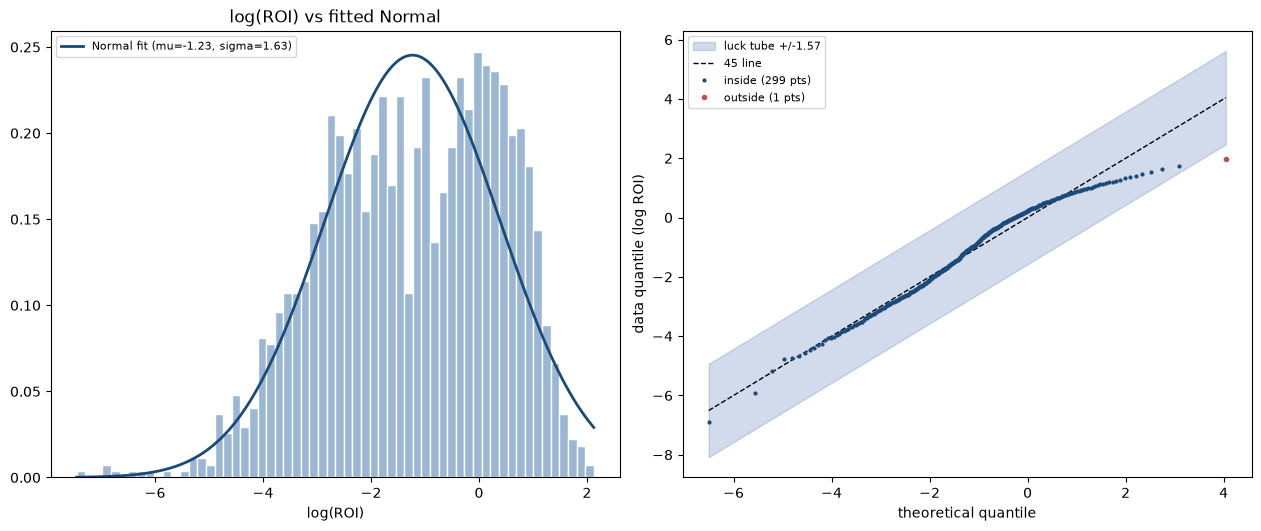

luck tube +/- 1.57 | real worst dev: 2.06


In [22]:
l_roi = np.log(roi)
mu_r, sd_r = l_roi.mean(), l_roi.std(ddof=0)

probs = np.linspace(1/(len(roi)+1), len(roi)/(len(roi)+1), 300)
emp   = np.quantile(l_roi, probs)
theo  = stats.norm.ppf(probs, mu_r, sd_r)

sims  = np.sort(rng.normal(mu_r, sd_r, size=(400, len(roi))), axis=1)
idx   = (probs*(len(roi)+1) - 1).clip(0, len(roi)-1).astype(int)
D_luck = np.max(np.abs(sims[:, idx] - theo), axis=1)
D95    = np.percentile(D_luck, 95)
D_real = np.max(np.abs(emp - theo))
outside = np.abs(emp - theo) > D95

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2), constrained_layout=True)
xs = np.linspace(l_roi.min(), l_roi.max(), 400)
axes[0].hist(l_roi, bins=60, density=True, color="#9bb7d4", edgecolor="white")
axes[0].plot(xs, stats.norm.pdf(xs, mu_r, sd_r), color="#1a4a7a", lw=2,
             label=f"Normal fit (mu={mu_r:.2f}, sigma={sd_r:.2f})")
axes[0].set_xlabel("log(ROI)"); axes[0].set_title("log(ROI) vs fitted Normal")
axes[0].legend(fontsize=8)

ax = axes[1]
ax.fill_between(theo, theo-D95, theo+D95, alpha=.25, color="#4c72b0",
                label=f"luck tube +/-{D95:.2f}")
ax.plot(theo, theo, "k--", lw=1, label="45 line")
ax.plot(theo[~outside], emp[~outside], ".", ms=4, color="#1a4a7a",
        label=f"inside ({(~outside).sum()} pts)")
ax.plot(theo[outside], emp[outside], ".", ms=6, color="#c44e52",
        label=f"outside ({outside.sum()} pts)")
ax.set_xlabel("theoretical quantile"); ax.set_ylabel("data quantile (log ROI)")
ax.legend(fontsize=8)

fig.savefig("histograms/luck_tube_qq_roi.png", dpi=300, bbox_inches="tight")
plt.show()
print("luck tube +/-", round(D95, 2), "| real worst dev:", round(D_real, 2))

In [23]:
params   = stats.lognorm.fit(rev, floc=0)
obs_chi2 = chisq_gof(rev, "lognorm", params, 2)[0]
hits     = 0
for _ in range(400):
    sim      = stats.lognorm.rvs(*params, size=len(rev), random_state=rng)
    p2       = stats.lognorm.fit(sim, floc=0)
    sim_chi2 = chisq_gof(sim, "lognorm", p2, 2)[0]
    hits    += (sim_chi2 >= obs_chi2)
print("observed chi2 =", round(obs_chi2, 1),
      "| simulation-based chi2 p =", (hits + 1) / 401)

observed chi2 = 135.5 | simulation-based chi2 p = 0.0024937655860349127


**📌 Inference :** 
> This section audited the winner two ways. The luck tube built from 400 fake industries kept 299 of 300 quantile points inside, with only the richest film escaping below the tube, meaning the model's tail allows bigger blockbusters than reality. 

> The simulation test gave chi square p = 0.0025, so at the alpha = 0.05 level the lognormal is formally rejected even though the visual fit is excellent, and because we fitted the parameters from the same data we calibrated the p value by simulation instead of using the textbook table.

## 8. Uncertainty — parametric bootstrap CIs and convergence

In [26]:
boots = np.array([stats.lognorm.fit(stats.lognorm.rvs(*params, size=len(rev), random_state=rng),
                                    floc=0) for _ in range(2_000)])
ci = np.percentile(boots, [2.5, 97.5], axis=0)

print("95% CI  s:", ci[:, 0].round(3), "  scale:", ci[:, 2].round(0))
print("SE(s) from simulation:", round(boots[:, 0].std(ddof=1), 4))

95% CI  s: [2.853 3.051]   scale: [11860384. 15616963.]
SE(s) from simulation: 0.0514


### 8.1 How many resamples? (convergence demo)

In [28]:
print('B (resamples) |  SE(s)  | 95% CI of s')
for B in [500, 1000, 3000, 10000]:
    bs = np.array([stats.lognorm.fit(stats.lognorm.rvs(*params, size=len(rev), random_state=rng),
                                     floc=0) for _ in range(B)])
    s_b = bs[:, 0]
    lo, hi = np.percentile(s_b, [2.5, 97.5])
    print(f'{B:12d} | {s_b.std(ddof=1):.4f} | [{lo:.3f}, {hi:.3f}]')
print('the full-data MLE s =', round(params[0], 4), ' never moves — resamples only re-measure it')

B (resamples) |  SE(s)  | 95% CI of s
         500 | 0.0493 | [2.846, 3.038]
        1000 | 0.0524 | [2.852, 3.052]


        3000 | 0.0513 | [2.850, 3.050]


       10000 | 0.0512 | [2.850, 3.050]
the full-data MLE s = 2.9503  never moves — resamples only re-measure it


**📌 Inference :**
>This section attached uncertainty by parametric bootstrap (fresh draws from the fitted lognormal rather than resamples of the data): 2,000 resamples put s between 2.85 and 3.05 with SE 0.051, and the convergence test from 500 to 10,000 resamples showed the interval barely moves, so the shape of the fit is a stable feature of this industry. 


>Resampling cannot create information, it only measures the uncertainty more precisely.

## 9. Summary of what was proven

- **Revenue and ROI are closest to lognormal.** The normal-on-log wins the χ² contest for both Revenue (135.5 vs 6,218
  for the raw normal) and ROI (103.0 vs 2,594.6).
- **Fit the log scale, by likelihood.** Raw moments are destroyed by the tail (MoM LL −35,105 vs MLE −32,140);
  on the log scale MoM ≡ MLE.
- **The fit is visually excellent but formally rejectable** (simulation χ² p = 0.0025; only the richest film
  escapes the luck tube) — χ² is used to rank and audit, not to crown a truth.
- **Uncertainty:** shape parameter s = 2.95, 95% CI [2.85, 3.05] (SE 0.051), stable from 500 to 10,000
  resamples.
